In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import tensorflow as tf
from google.colab import files

In [3]:
os.makedirs('model/tensorflow', exist_ok=True)
os.makedirs('images', exist_ok=True)

uploaded = files.upload()
for filename in uploaded.keys():
  dest = os.path.join('model/tensorflow', filename)
  os.rename(filename, dest)
  print(f"Moved '{filename}' -> '{dest}'")

Saving frozen_inference_graph.pb to frozen_inference_graph.pb
Saving object_detection_classes_coco.txt to object_detection_classes_coco.txt
Saving ssd_mobilenet_v2_coco_2018_03_29.pbtxt to ssd_mobilenet_v2_coco_2018_03_29.pbtxt
Moved 'frozen_inference_graph.pb' -> 'model/tensorflow/frozen_inference_graph.pb'
Moved 'object_detection_classes_coco.txt' -> 'model/tensorflow/object_detection_classes_coco.txt'
Moved 'ssd_mobilenet_v2_coco_2018_03_29.pbtxt' -> 'model/tensorflow/ssd_mobilenet_v2_coco_2018_03_29.pbtxt'


In [6]:
os.makedirs('model/images', exist_ok=True)

uploaded = files.upload()
for filename in uploaded.keys():
  dest = os.path.join('model/images', filename)
  os.rename(filename, dest)
  print(f"Moved '{filename}' -> '{dest}'")

Saving elephant.jpg to elephant (2).jpg
Saving pedestrian.jpg to pedestrian (2).jpg
Moved 'elephant (2).jpg' -> 'model/images/elephant (2).jpg'
Moved 'pedestrian (2).jpg' -> 'model/images/pedestrian (2).jpg'


In [7]:
pb_file = 'model/tensorflow/frozen_inference_graph.pb'
classes_file = 'model/tensorflow/object_detection_classes_coco.txt'

print("\nLoading TensorFlow Model...")
with tf.io.gfile.GFile(pb_file, 'rb') as f:
  graph_def = tf.compat.v1.GraphDef()
  graph_def.ParseFromString(f.read())

with tf.Graph().as_default() as detection_graph:
  tf.import_graph_def(graph_def, name='')
  image_tensor = detection_graph.get_tensor_by_name('image_tensor:0')
  detection_boxes = detection_graph.get_tensor_by_name('detection_boxes:0')
  detection_scores = detection_graph.get_tensor_by_name('detection_scores:0')
  detection_classes = detection_graph.get_tensor_by_name('detection_classes:0')

  with open(classes_file, 'r') as f:
    classes = f.read().split('\n')

print("Model Loaded Successfully")


Loading TensorFlow Model...
Model Loaded Successfully


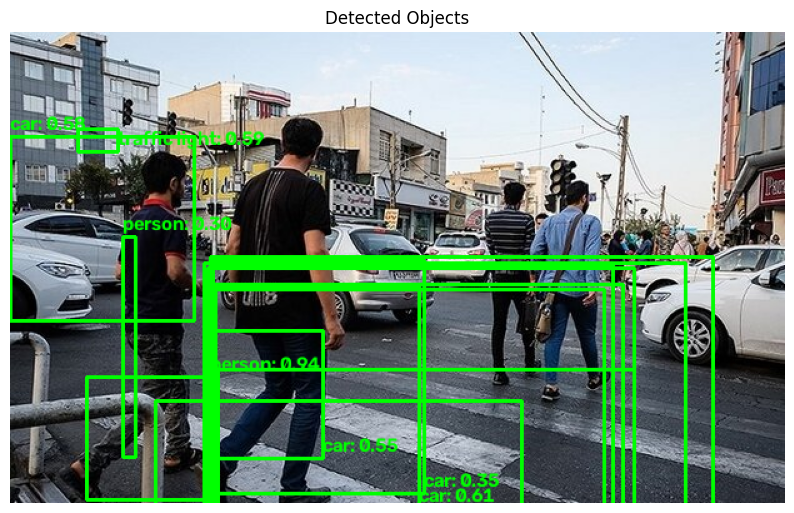

In [14]:
def detect_objects_tf(img_path, min_score=0.3):
  img = cv2.imread(img_path)
  if img is None:
    print(f"Error: Could Not Read Image From {img_path}")
    return

  img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  img_expanded = np.expand_dims(img_rgb, axis=0)

  with tf.compat.v1.Session(graph=detection_graph) as sess:
    (boxes, scores, out_classes) = sess.run([detection_boxes, detection_scores, detection_classes], feed_dict={image_tensor: img_expanded})

  h, w, _ = img.shape
  detected_count = 0

  for i in range(len(scores[0])):
    if scores[0][i] > min_score:
      detected_count += 1
      score = scores[0][i]

      class_id = int(out_classes[0][i])
      class_name = classes[class_id - 1] if class_id > 0 else 'Unknown'
      ymin, xmin, ymax, xmax = boxes[0][i]
      left, right, top, bottom = int(xmin * w), int(ymin * h), int(xmax * w), int(ymax * h)

      cv2.rectangle(img, (left, top), (right, bottom), (0, 255, 0), 2)
      cv2.putText(img, f"{class_name}: {score:.2f}", (left, top - 5),
                  cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

  plt.figure(figsize=(10, 8))

  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.title("Detected Objects")
  plt.axis('off')

  plt.show()

detect_objects_tf('model/images/pedestrian (2).jpg')


Detecting Objects In Images...



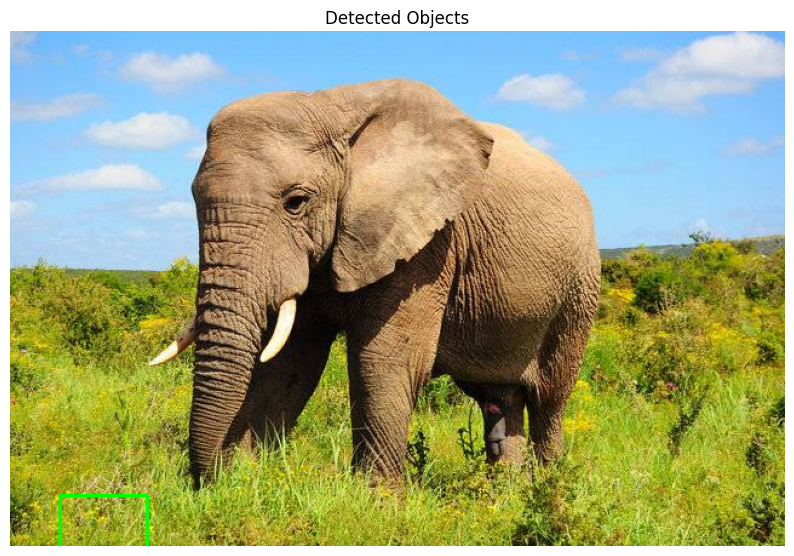

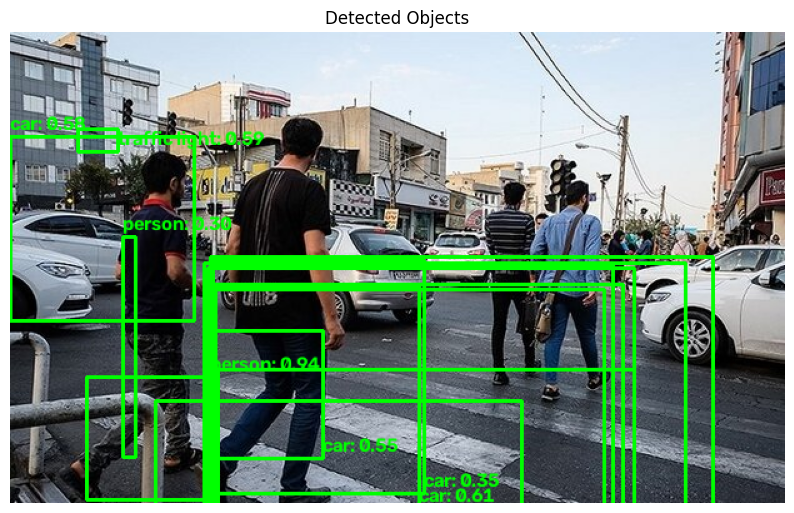

In [12]:
print("\n" + "=" * 60)
print("Detecting Objects In Images...")
print("=" * 60 + "\n")

image_files = [f for f in os.listdir('model/images') if f.endswith('.jpg')]

for image_file in image_files:
  image_path = os.path.join('model/images', image_file)
  detect_objects_tf(image_path, min_score=0.3)
  print("=" * 40)